In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
# racine specification
ROOT = Path.cwd().parent

sys.path.append(str(ROOT))

print("Project root:", ROOT)

Project root: /home/kenzi/Desktop/S3/ML_FOR_CS/SENTINEL-U


In [3]:
from src.data.dataset import load_dataset
from src.data.preprocessing import (
    check_duplicates,
    check_invalid_logins,
    check_missing_values,
    check_negative_values,
    convert_timestamp)

In [4]:
data_path = ROOT/"Data"/"raw"/"auth_hourly.csv"
df = load_dataset(data_path)
df.head()

,timestamp,user_id,peer_group,hour,day_of_week,is_weekend,off_hours,logins,failed_logins,distinct_ips,distinct_hosts,mb_out,dns_queries,country,foreign_country,split,benign_event,is_attack,attack_type
0,2026-09-07 00:00:00,u000,student,0,0,0,1,1,0,1,1,0.66,10,MA,0,train,none,0,none
1,2026-09-07 00:00:00,u001,student,0,0,0,1,0,0,0,0,0.84,53,MA,0,train,none,0,none
2,2026-09-07 00:00:00,u002,student,0,0,0,1,0,0,0,0,0.40,1,MA,0,train,none,0,none
3,2026-09-07 00:00:00,u003,student,0,0,0,1,0,0,0,0,1.02,38,MA,0,train,none,0,none
4,2026-09-07 00:00:00,u004,student,0,0,0,1,0,0,0,0,0.17,1,MA,0,train,none,0,none


In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 264888
Number of columns: 19


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 264888 entries, 0 to 264887
Data columns (total 19 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   timestamp        264888 non-null  object 
 1   user_id          264888 non-null  object 
 2   peer_group       264888 non-null  object 
 3   hour             264888 non-null  int64  
 4   day_of_week      264888 non-null  int64  
 5   is_weekend       264888 non-null  int64  
 6   off_hours        264888 non-null  int64  
 7   logins           264888 non-null  int64  
 8   failed_logins    264888 non-null  int64  
 9   distinct_ips     264888 non-null  int64  
 10  distinct_hosts   264888 non-null  int64  
 11  mb_out           264888 non-null  float64
 12  dns_queries      264888 non-null  int64  
 13  country          264888 non-null  object 
 14  foreign_country  264888 non-null  int64  
 15  split            264888 non-null  object 
 16  benign_event     264888 non-null  obje

In [7]:
df.describe()

,hour,day_of_week,is_weekend,off_hours,logins,failed_logins,distinct_ips,distinct_hosts,mb_out,dns_queries,foreign_country,is_attack
count,264888.0000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000,264888.000000
mean,11.5000,3.003262,0.286219,0.672850,0.371274,0.021485,0.267943,0.272734,2.481176,21.437109,0.003681,0.005821
std,6.9222,1.999820,0.451994,0.469173,1.174031,0.840846,0.509395,0.510043,29.338638,24.668184,0.060558,0.076075
min,0.0000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.020000,0.000000,0.000000,0.000000
25%,5.7500,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.270000,5.000000,0.000000,0.000000
50%,11.5000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.790000,14.000000,0.000000,0.000000
75%,17.2500,5.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.960000,30.000000,0.000000,0.000000
max,23.0000,6.000000,1.000000,1.000000,150.000000,143.000000,30.000000,10.000000,4602.110000,727.000000,1.000000,1.000000


In [8]:
print(df["split"].value_counts())

split
train         130488
test          100800
validation     33600
Name: count, dtype: int64


In [9]:
split_percentages = (
    df["split"].value_counts(normalize=True) * 100
)

display(split_percentages)

split
train         49.261575
test          38.053819
validation    12.684606
Name: proportion, dtype: float64

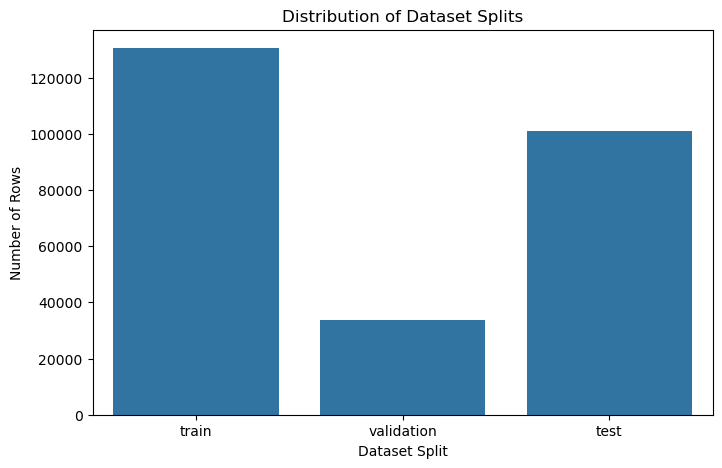

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="split",
    order=["train", "validation", "test"]
)

plt.title("Distribution of Dataset Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Rows")

plt.show()

In [11]:
missing_values = check_missing_values(df)

display(missing_values)

timestamp          0
user_id            0
peer_group         0
hour               0
day_of_week        0
is_weekend         0
off_hours          0
logins             0
failed_logins      0
distinct_ips       0
distinct_hosts     0
mb_out             0
dns_queries        0
country            0
foreign_country    0
split              0
benign_event       0
is_attack          0
attack_type        0
dtype: int64

In [12]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

display(missing_percentage)

timestamp          0.0
user_id            0.0
peer_group         0.0
hour               0.0
day_of_week        0.0
is_weekend         0.0
off_hours          0.0
logins             0.0
failed_logins      0.0
distinct_ips       0.0
distinct_hosts     0.0
mb_out             0.0
dns_queries        0.0
country            0.0
foreign_country    0.0
split              0.0
benign_event       0.0
is_attack          0.0
attack_type        0.0
dtype: float64

In [13]:
duplicates = check_duplicates(df)

print("Nombre de doublons :", duplicates)

Nombre de doublons : 0


In [14]:
df = convert_timestamp(df)

In [15]:
pd.to_datetime(df["timestamp"], errors="coerce")

0        2026-09-07 00:00:00
1        2026-09-07 00:00:00
2        2026-09-07 00:00:00
3        2026-09-07 00:00:00
4        2026-09-07 00:00:00
                 ...        
264883   2026-11-01 23:00:00
264884   2026-11-01 23:00:00
264885   2026-11-01 23:00:00
264886   2026-11-01 23:00:00
264887   2026-11-01 23:00:00
Name: timestamp, Length: 264888, dtype: datetime64[ns]

In [16]:
invalid_logins = check_invalid_logins(df)

print("Nombre de lignes avec des connexions incohérentes :",
      len(invalid_logins))

display(invalid_logins)

Nombre de lignes avec des connexions incohérentes : 0


,timestamp,user_id,peer_group,hour,day_of_week,is_weekend,off_hours,logins,failed_logins,distinct_ips,distinct_hosts,mb_out,dns_queries,country,foreign_country,split,benign_event,is_attack,attack_type


In [17]:
negative_values = check_negative_values(df)

print("Nombre de valeurs négatives :")

for column, count in negative_values.items():
    print(f"{column}: {count}")

Nombre de valeurs négatives :
logins: 0
failed_logins: 0
distinct_ips: 0
distinct_hosts: 0
mb_out: 0
dns_queries: 0


Variables numériques : ['hour', 'day_of_week', 'is_weekend', 'off_hours', 'logins', 'failed_logins', 'distinct_ips', 'distinct_hosts', 'mb_out', 'dns_queries', 'foreign_country', 'is_attack']


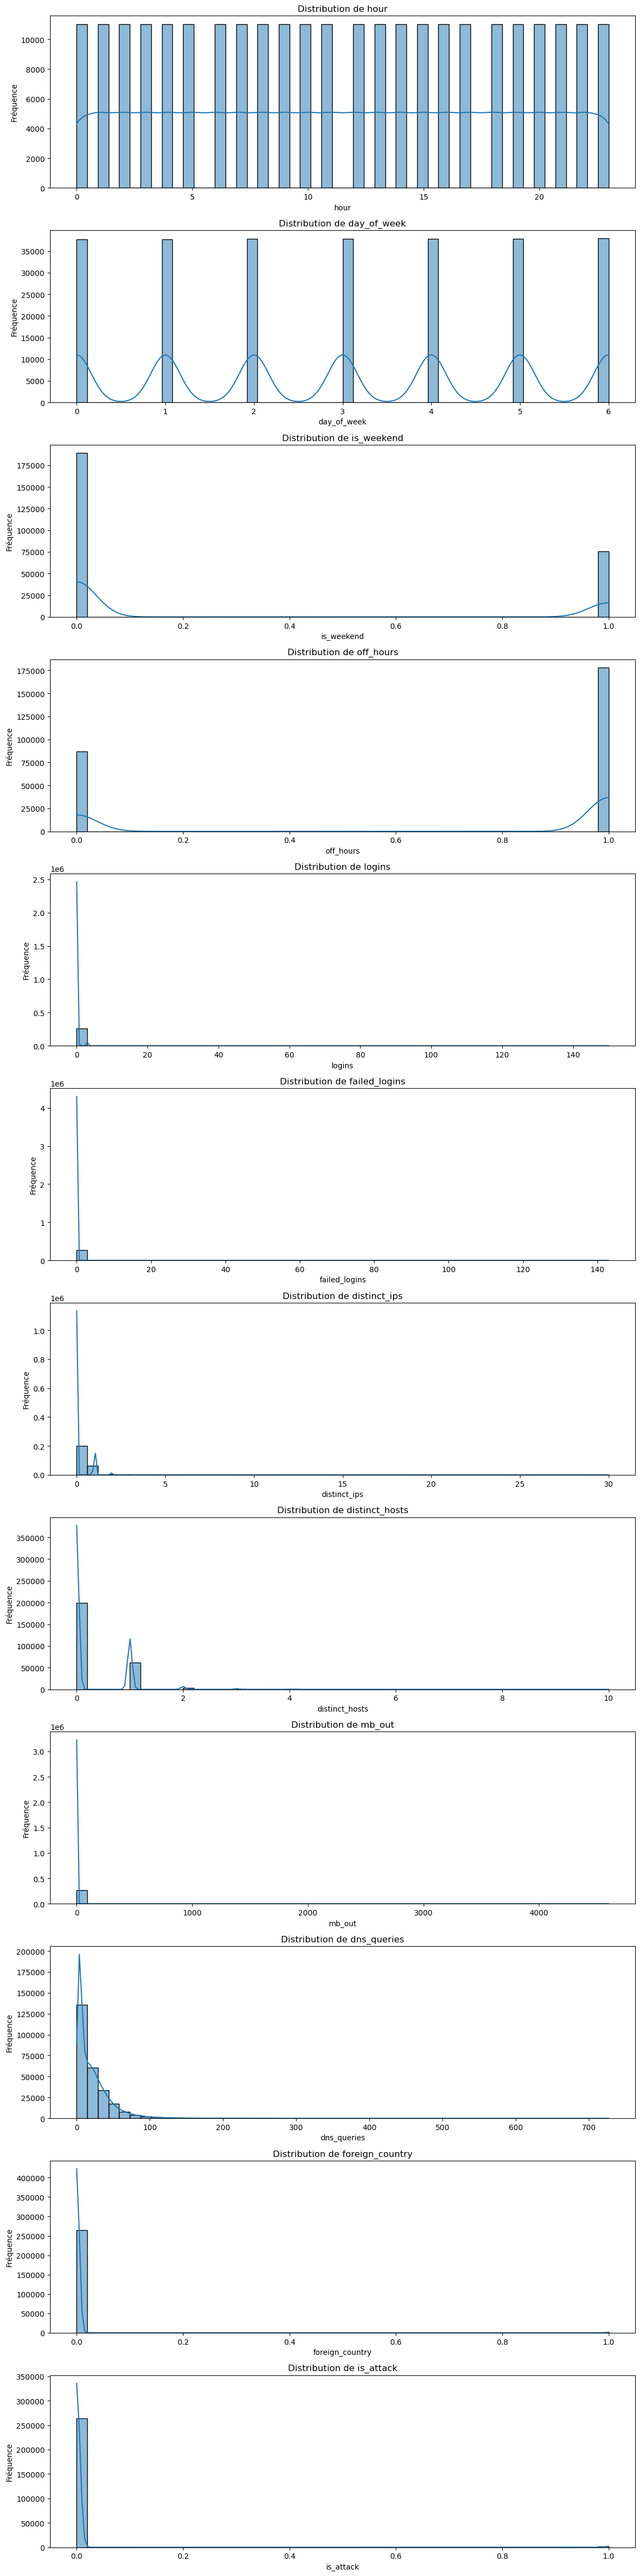

In [19]:
# Sélectionner toutes les colonnes numériques
numeric_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns

print("Variables numériques :", list(numeric_columns))

# Nombre de variables
n = len(numeric_columns)

# Créer les graphiques
fig, axes = plt.subplots(
    nrows=n,
    ncols=1,
    figsize=(12, 4 * n)
)

for ax, col in zip(axes, numeric_columns):

    sns.histplot(
        data=df,
        x=col,
        bins=50,
        kde=True,
        ax=ax
    )

    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

In [21]:
df["timestamp"] = pd.to_datetime(df["timestamp"])

df["hour"] = df["timestamp"].dt.hour

activity = (
    df.groupby(["peer_group", "hour"])["logins"]
      .mean()
      .reset_index()
)

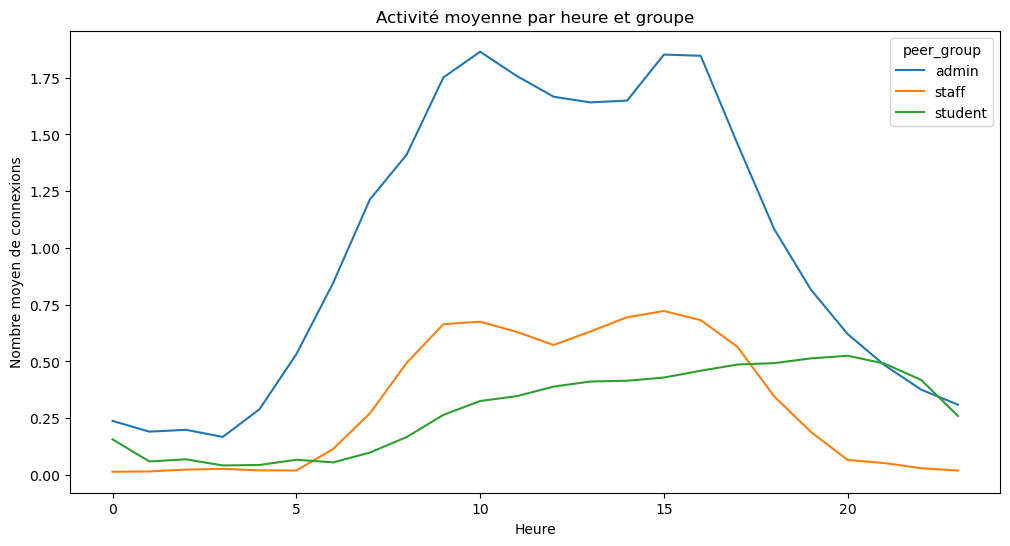

In [22]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=activity,
    x="hour",
    y="logins",
    hue="peer_group"
)

plt.title("Activité moyenne par heure et groupe")
plt.xlabel("Heure")
plt.ylabel("Nombre moyen de connexions")

plt.show()